# Hybrid Product Recommendation Model (Supervised)

**Objective:**
  * Group products by similarity, create the attributes required for each product category,
   based on the EDA, using the K-Means and K-Prototypes clustering algorithms
  * Recommend alternative products based on similarity
  * Recommend complementary products based on the customer's selection
  * The goal is to infer the sale of certain products based on the organization's commercial strategies

**Dataset**:
  * The datasets are located in the TFM folder (not included in this repository)

# Datasets used

### Table Productos_Categoria_HigieneOral

Contains detailed product information, product details and prices per supplier.




In [1]:
!pip install kmodes==0.12.2

In [2]:
!pip install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 11.6 MB/s  0:00:00


0. Loading libraries and defining common functions


In [3]:
import re
import unicodedata
import ast
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder, OneHotEncoder, MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score

from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from joblib import Parallel, delayed
from rapidfuzz import fuzz

import warnings
warnings.filterwarnings('ignore')

### Common functions


#### Text normalization functions


In [4]:
# @title
sinonimos = {}

dental_equivalencias = ['PASTA DENTAL', 'DENTIFRICO', 'GEL DENTAL']
infantil_equivalencias = ["NINO", "NINOS", "NIÑO", "NIÑOS", "KIDS", "INFANTES"]
blanqueador_equivalencias = ["BLANQUEADORA", "BLANQUEADOR", "WHITE", "WHITENING", "LUMINOUS"]
carbon_equivalencias = ["CHARCOAL","CARBONES"]
herbal_equivalencias = ["HIERBAS","HIERBA"]
alcalina_equivalencias = ['ALCALINA', 'ALCALIN', 'MAX', 'MAX PLUS', 'GOLD',
                           'ALKALINA', 'ALKALINE', 'E-91', 'E-92', 'E-93',
                           'E-95', 'E-96', 'E91', 'E92', 'E93', 'E95', 'E96']
zincarbon_equivalencias = ['ZINC CARBON', 'ZINC-CARBON', 'BLUE', 'CARBON ZINC',
                            '915', '912', '950', '1212', '1215', '1235', '1250']

sinonimos.update({k: "CREMA DENTAL" for k in dental_equivalencias})
sinonimos.update({k: "INFANTIL" for k in infantil_equivalencias})
sinonimos.update({k: "BLANQUEADOR" for k in blanqueador_equivalencias})
sinonimos.update({k: "CARBON" for k in carbon_equivalencias})
sinonimos.update({k: "HERBAL" for k in herbal_equivalencias})
sinonimos.update({k: 'ALCALINA'    for k in alcalina_equivalencias})
sinonimos.update({k: 'ZINC-CARBON' for k in zincarbon_equivalencias})

# ── Reference table TipoPila (battery type) → derived attributes ───────────────────────
PILA_REFERENCIA = {
    # TipoPila       Tecnologia      Voltage
    'AA':           ('ALCALINA',    '1.5V'),
    'AAA':          ('ALCALINA',    '1.5V'),
    'C':            ('ALCALINA',    '1.5V'),
    'D':            ('ALCALINA',    '1.5V'),
    'A76':          ('ALCALINA',    '1.5V'),
    'AAAA':         ('ALCALINA',    '1.5V'),
    '9V':           ('ALCALINA',    '9V'),
    'A23':          ('ALCALINA',    '12V'),
    'A27':          ('ALCALINA',    '12V'),
    'CR2016':       ('LITIO',       '3V'),
    'CR2025':       ('LITIO',       '3V'),
    'CR2032':       ('LITIO',       '3V'),
    'CR2450':       ('LITIO',       '3V'),
    'ECR 2016':     ('LITIO',       '3V'),
    'ECR 2025':     ('LITIO',       '3V'),
    'ECR 2032':     ('LITIO',       '3V'),
    'ECR 2450':     ('LITIO',       '3V'),
    'AZ13':         ('ZINC-AIRE',   '1.45V'),
    'AZ 13':        ('ZINC-AIRE',   '1.45V'),
    'AZ312':        ('ZINC-AIRE',   '1.45V'),
    'AZ 312':       ('ZINC-AIRE',   '1.45V'),
    '377/376':      ('OXIDO PLATA', '1.55V'),
    '364/363':      ('OXIDO PLATA', '1.55V'),
}

## ____________________________________________________________________##
def normalizar_texto(texto):
    if pd.isna(texto):
        return ""

    texto = str(texto).strip().upper()

    # remove accents
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))

    # remove leading numbering
    if not re.match(r'^\d+\s*(GR|GRS|G|ML)\b', texto):
      texto = re.sub(r'^\d+(\.\d+)*\s*', '', texto)

    # clean symbols first, keeping spaces
    texto = re.sub(r"[^A-Z0-9\s]", " ", texto)

    # normalize whitespace (temporary)
    texto = re.sub(r"\s+", " ", texto).strip()

    # apply synonyms by whole word/phrase
    for original, reemplazo in sinonimos.items():
        original_norm = re.sub(r"[^A-Z0-9\s]", " ", original.upper())
        original_norm = re.sub(r"\s+", " ", original_norm).strip()

        patron = r'\b' + re.escape(original_norm) + r'\b'
        texto = re.sub(patron, reemplazo.upper(), texto)

    # normalize weights: 70GR, 70 GR, 70 GRS -> 70 GRS
    texto = re.sub(r'\b(\d+)\s*(GRS|GR|G)\b', r'\1 GRS', texto)

    # normalize milliliters: 100ML, 100 ML -> 100 ML
    texto = re.sub(r'\b(\d+)\s*(ML)\b', r'\1 ML', texto)

    # final whitespace normalization
    texto = re.sub(r"\s+", " ", texto).strip()

    return texto

# ============================
# normalize text in product names (denominacion)
# ============================
def preparar_productos(productos):
    productos = productos.copy()

    productos["ctdbdeno_norm"] = productos["ctdbdeno"].apply(normalizar_texto)
    productos["pddbdeno_norm"] = productos["pddbdeno"].apply(normalizar_texto)

    return productos

# ============================
# for category 273 - BATTERIES (PILAS)
# ============================
def inferir_atributos_pila(productos_resultado):
    """
    Derives Tecnologia (technology) and Voltage directly from TipoPila
    using the reference table. It does not depend on the product name
    or on regex — it simply performs a dictionary lookup.
    """
    if 'TipoPila' not in productos_resultado.columns:
        return productos_resultado

    def _lookup(tipo_pila, campo):
        if pd.isna(tipo_pila):
            return np.nan
        ref = PILA_REFERENCIA.get(str(tipo_pila).strip())
        if ref is None:
            return np.nan
        return ref[0] if campo == 'Tecnologia' else ref[1]

    productos_resultado['Tecnologia'] = productos_resultado['TipoPila'].apply(
        lambda x: _lookup(x, 'Tecnologia')
    )
    productos_resultado['Voltage'] = productos_resultado['TipoPila'].apply(
        lambda x: _lookup(x, 'Voltage')
    )

    return productos_resultado

#### Text search functions


In [5]:
# @title
# ============================
# fuzzy search over categories
# ============================
def buscar_categorias_fuzzy(query, categorias, threshold):

    # normalize query
    query_norm = normalizar_texto(query)
    print("Normalized query:", query_norm)

    categorias = categorias.copy()

    # normalize categories directly
    categorias["ctdbdeno"] = categorias["ctdbdeno"].apply(
        normalizar_texto
    )

    # compute score
    categorias["score"] = categorias["ctdbdeno"].apply(
        lambda x: fuzz.partial_ratio(query_norm, x)
    )

    # filter
    resultado = categorias[
        (categorias["ctdbacti_clean"] == "s") &
        (categorias["score"] >= threshold)
    ].copy()

    # sort
    resultado = resultado.sort_values(
        by=["score", "iddbprca"],
        ascending=[False, True]
    ).reset_index(drop=True)

    # final columns
    resultado = resultado[
        ["iddbprcp", "iddbprca", "ctdbdeno", "score"]
    ]

    # list for later use
    lista_ids = resultado[
        ["iddbprcp", "iddbprca"]
    ].to_dict(orient="records")

    return resultado[
        ["iddbprcp", "iddbprca", "ctdbdeno", "score"]
    ].reset_index(drop=True)

# ============================
# unique category search - 1. RapidFuzz - 2. TF-IDF
# ============================
def buscar_categorias_consulta(
    query,
    productos,
    threshold_fuzzy,
    threshold_tfidf
):
    productos = preparar_productos(productos)

    consulta_norm = normalizar_texto(query)
    print("Normalized query:", consulta_norm)

     # clean category directly
    productos["ctdbdeno"] = productos["ctdbdeno"].apply(normalizar_texto)

    # ============================
    # 1. Unique categories
    # ============================
    categorias = productos[
        ["iddbprcp", "iddbprca", "ctdbdeno", "ctdbdeno_norm"]
    ].drop_duplicates().reset_index(drop=True)

    # ============================
    # 2. RapidFuzz over categories
    # ============================
    categorias["score_fuzzy"] = categorias["ctdbdeno_norm"].apply(
        lambda x: fuzz.partial_ratio(consulta_norm, x)
    )

    resultado_fuzzy = categorias[
        categorias["score_fuzzy"] >= threshold_fuzzy
    ].copy()

    if not resultado_fuzzy.empty:

        # If there are 98% matches
        if (resultado_fuzzy["score_fuzzy"] == 100).any():
            resultado_fuzzy = resultado_fuzzy[
                resultado_fuzzy["score_fuzzy"] >= 98
            ].copy()

        resultado = resultado_fuzzy.sort_values(
            by=["score_fuzzy", "iddbprcp", "iddbprca"],
            ascending=[False, True, True]
        ).copy()

        resultado["score"] = resultado["score_fuzzy"]

        print("⭐ Method used: RapidFuzz")

        return resultado[
            ["iddbprcp", "iddbprca", "ctdbdeno", "score"]
        ].drop_duplicates().reset_index(drop=True)

    # ============================
    # 3. TF-IDF fallback over products
    # ============================
    print("RapidFuzz found no results. Falling back to TF-IDF search.")

    vectorizer = TfidfVectorizer()
    matriz_tfidf = vectorizer.fit_transform(productos["pddbdeno_norm"])
    consulta_vec = vectorizer.transform([consulta_norm])

    similitudes = cosine_similarity(consulta_vec, matriz_tfidf).flatten()

    productos["score_tfidf"] = similitudes

    productos_match = productos[
        productos["score_tfidf"] >= threshold_tfidf
    ].copy()

    if productos_match.empty:
        print("No categories found.")
        return pd.DataFrame(columns=["iddbprcp", "iddbprca", "ctdbdeno", "score"])

    resultado = (
        productos_match
        .groupby(["iddbprcp", "iddbprca", "ctdbdeno"], as_index=False)
        .agg(score=("score_tfidf", "max"))
        .sort_values(
            by=["score", "iddbprcp", "iddbprca"],
            ascending=[False, True, True]
        )
    )

    print("⭐ Method used: TF-IDF")

    return resultado[
        ["iddbprcp", "iddbprca", "ctdbdeno", "score"]
    ].reset_index(drop=True)

#### Functions to generate attribute columns


In [6]:
# @title

# ============================
# BUILD dataset Categories -> Attributes -> Values
# ============================
def build_categorias_atributo_valor(
    categorias_resultado: pd.DataFrame,
    cat_atributos: pd.DataFrame,
    atributos: pd.DataFrame,
    cat_atr_valor: pd.DataFrame,
) -> pd.DataFrame:

    # ── Filter only the subcategories in categorias_resultado ────────────────
    subcats = categorias_resultado['iddbprca'].unique()
    cat_atributos_filtrado = cat_atributos[
        cat_atributos['Subcategoria'].isin(subcats)
    ].copy()

    # ── Step 1: categorias_resultado → Categorias_Atributos ──────────────────
    merged = categorias_resultado.merge(
        cat_atributos_filtrado,
        left_on  = 'iddbprca',
        right_on = 'Subcategoria',
        how      = 'inner'
    )
    # ── Step 2: → Atributos ──────────────────────────────────────────────────
    merged = merged.merge(
        atributos,
        on  = 'AtributoId',
        how = 'left'
    )
    # ── Step 3: → Categorias_Atributos_Valor ─────────────────────────────────
    merged = merged.merge(
        cat_atr_valor,
        on  = 'CatAtrId',
        how = 'left'
    )

    return merged.reset_index(drop=True)

# ============================
# BUILD base productos_resultado
# ============================
COLUMNAS_COMUNES_DBF = [
    "Marca",
    "UnidadPeso",
    "UnidadCaja",
    "PrecioUnidad",
    "PrecioCaja"
]

def crear_atributos_estructurados(productos_match):
    columnas = {
        "iddbprcp": "Categoria",
        "iddbprca": "Subcategoria",
        "iddbprod": "ProductoId",
        "pddbdeno": "Denominacion",
        "mcdbdeno": "Marca",
        "umdbdeno": "UnidadPeso",
        "umdbdein": "UnidadCaja",
        "ppdbpain": "PrecioUnidad",
        "ppdbppaf": "PrecioCaja"
    }

    productos_resultado = productos_match[list(columnas.keys())].copy()
    productos_resultado = productos_resultado.rename(columns=columnas)

    productos_resultado["Denominacion"] = (
        productos_resultado["Denominacion"]
        .astype(str)
        .str.strip()
    )

    productos_resultado["Denominacion_Norm"] = (
        productos_resultado["Denominacion"]
        .apply(normalizar_texto)
        .str.upper()
    )

    for col in ["Marca", "UnidadPeso", "UnidadCaja"]:
        productos_resultado[col] = (
            productos_resultado[col]
            .apply(normalizar_texto)
            .str.upper()
        )
    return productos_resultado.reset_index(drop=True)

# ============================
# BUILD DYNAMIC COLUMNS
# ============================
def crear_atributos_generados(productos_resultado, categorias_atributo_valor, threshold):
    productos_resultado = productos_resultado.copy()
    cat_attr_val = categorias_atributo_valor.copy()

    # ── Keep only subcategories present in productos_resultado ───────────
    subcats_activas = productos_resultado['Subcategoria'].unique()
    cat_attr_val = cat_attr_val[
        cat_attr_val['Subcategoria'].isin(subcats_activas)
    ].copy()

    # Normalize attributes
    cat_attr_val["AtributoNombre"] = (
        cat_attr_val["AtributoNombre"]
        .astype(str)
        .str.strip()
    )

    # Drop common attributes that already come from products/DBF
    cat_attr_val = cat_attr_val[
        ~cat_attr_val["AtributoNombre"].isin(COLUMNAS_COMUNES_DBF)
    ].copy()

    # Normalize Valor
    cat_attr_val["Valor"] = (
        cat_attr_val["Valor"]
        .astype(str)
        .apply(normalizar_texto)
        .str.upper()
    )

    # Normalize ValorDefault manteniendo NaN
    cat_attr_val["ValorDefault"] = cat_attr_val["ValorDefault"].apply(
        lambda x: normalizar_texto(x).upper() if pd.notna(x) else np.nan
    )

    # Create only the columns of attributes active in these subcategories
    columnas_atributos = (
        cat_attr_val["AtributoNombre"]
        .dropna()
        .drop_duplicates()
        .tolist()
    )

    for col in columnas_atributos:
        if col not in productos_resultado.columns:
            productos_resultado[col] = np.nan

    # Iterate over products
    for idx, row in productos_resultado.iterrows():
        subcategoria = row["Subcategoria"]
        denominacion = row["Denominacion_Norm"]

        atributos_subcat = cat_attr_val[
            cat_attr_val["Subcategoria"] == subcategoria
        ]

        for atributo_nombre, grupo_attr in atributos_subcat.groupby("AtributoNombre"):
            valores_default = (
                grupo_attr["ValorDefault"].dropna().unique().tolist()
            )
            valor_encontrado = valores_default[0] if len(valores_default) > 0 else np.nan
            valores_posibles = (
                grupo_attr["Valor"].dropna().unique().tolist()
            )

            if atributo_nombre == "Gramaje":
                for valor in valores_posibles:
                    valor_norm = normalizar_texto(valor).upper()
                    patron = r'\b' + re.escape(valor_norm) + r'\b'
                    if re.search(patron, denominacion):
                        valor_encontrado = valor_norm
                        break
            else:
                for valor in valores_posibles:
                    valor_norm = normalizar_texto(valor).upper()
                    patron = r'\b' + re.escape(valor_norm) + r'\b'
                    if re.search(patron, denominacion):
                        valor_encontrado = valor_norm
                        break
                    if len(valor_norm) >= 5:
                        score = fuzz.token_set_ratio(valor_norm, denominacion)
                        if score >= threshold:
                            valor_encontrado = valor_norm
                            break

            productos_resultado.at[idx, atributo_nombre] = valor_encontrado

    return productos_resultado.reset_index(drop=True)

#### Functions to compute scores - recommended products


In [7]:
# @title
# ============================
# COMPUTE QUERY SCORE
# ============================
def calcular_score_consulta(productos_score, consulta_query):
    productos_score = productos_score.copy()
    consulta_norm = normalizar_texto(consulta_query).upper()
    columnas_base = [
        "Categoria",
        "Subcategoria",
        "ProductoId",
        "Denominacion",
        "Denominacion_Norm",
        "Score",
        "ScoreAtributos",
        "ScoreConsulta"
    ]
    columnas_atributos = [
        col for col in productos_score.columns
        if col not in columnas_base
    ]
    def construir_texto_producto(row):
        partes = [row["Denominacion_Norm"]]
        for col in columnas_atributos:
            valor = row[col]

            if pd.notna(valor):
                partes.append(normalizar_texto(valor).upper())

        return " ".join(partes)

    def calcular_similitud_consulta(texto_producto):

        texto_producto = normalizar_texto(texto_producto).upper()
        # overall fuzzy similarity
        score_fuzzy = fuzz.token_set_ratio(
            consulta_norm,
            texto_producto
        ) / 100
        # query token coverage
        tokens_consulta = set(consulta_norm.split())

        tokens_encontrados = [
            token for token in tokens_consulta
            if re.search(r'\b' + re.escape(token) + r'\b', texto_producto)
        ]

        cobertura_tokens = len(tokens_encontrados) / len(tokens_consulta)
        # strong penalty if an important word such as CARBON is missing
        score_final = score_fuzzy * cobertura_tokens

        return score_final

    productos_score["TextoScoreConsulta"] = productos_score.apply(
        construir_texto_producto,
        axis=1
    )
    productos_score["ScoreConsulta"] = productos_score["TextoScoreConsulta"].apply(
        calcular_similitud_consulta
    )
    return productos_score

# ============================
# COMPUTE PRODUCT SCORE
# ============================
def calcular_score_productos(productos_resultado, atributos, atr_valor, consulta_query):
    productos_score = productos_resultado.copy()
    atr_valor_tmp = atr_valor.copy()

    # Normalize
    atr_valor_tmp["AtributoNombre"] = (
        atr_valor_tmp["AtributoNombre"]
        .astype(str)
        .str.strip()
    )
    atr_valor_tmp["Valor"] = (
        atr_valor_tmp["Valor"]
        .astype(str)
        .apply(normalizar_texto)
        .str.upper()
    )
    atr_valor_tmp["ValorDefault"] = atr_valor_tmp["ValorDefault"].apply(
        lambda x: normalizar_texto(x).upper() if pd.notna(x) else np.nan
    )

    columnas_base = [
        "Categoria", "Subcategoria", "ProductoId",
        "Denominacion", "Denominacion_Norm", "Score"
    ]
    columnas_atributos = [
        col for col in productos_score.columns
        if col not in columnas_base
    ]

    scores = []

    for _, row in productos_score.iterrows():
        subcategoria = row["Subcategoria"]
        score_total  = 0

        for col in columnas_atributos:
            valor_producto = row[col]

            if pd.isna(valor_producto):
                continue

            valor_producto_norm = normalizar_texto(valor_producto).upper()

            # ── Look up AtributoId and PesoAtributo ─────────────────────────────
            # ✅ now looks up in categorias_atributo_valor (atr_valor_tmp)
            atributo_match = atr_valor_tmp[
                (atr_valor_tmp["Subcategoria"]   == subcategoria) &
                (atr_valor_tmp["AtributoNombre"] == col)
            ].drop_duplicates(subset=["AtributoId", "PesoAtributo"])

            if atributo_match.empty:
                continue

            peso_atributo = atributo_match["PesoAtributo"].iloc[0]

            if pd.isna(peso_atributo):
                peso_atributo = 0

            # ── Look up PesoValor ──────────────────────────────────────────────
            valor_match = atr_valor_tmp[
                (atr_valor_tmp["Subcategoria"]   == subcategoria) &
                (atr_valor_tmp["AtributoNombre"] == col) &
                (atr_valor_tmp["Valor"]          == valor_producto_norm)
            ]

            if valor_match.empty:
                peso_valor = 0
            else:
                valor_default = valor_match["ValorDefault"].iloc[0]

                if pd.notna(valor_default) and valor_default == valor_producto_norm:
                    peso_valor = 0
                else:
                    peso_valor = valor_match["PesoValor"].iloc[0]
                    if pd.isna(peso_valor):
                        peso_valor = 0

            score_total += peso_atributo * peso_valor

        scores.append(score_total)

    productos_score["ScoreAtributos"] = scores

    productos_score = calcular_score_consulta(
        productos_score,
        consulta_query
    )

    productos_score["Score"] = (
        productos_score["ScoreConsulta"] * 0.7 +
        productos_score["ScoreAtributos"] * 0.3
    )

    productos_score = productos_score.sort_values(
        by="Score",
        ascending=False
    )
    return productos_score
def obtener_top_recomendaciones(productos_resultado, top_n=10, min_score_consulta=0.8,
                                 min_resultados=5, por_subcategoria=False):

    pasos = [1.0, 0.85, 0.70, 0.55, 0.40]
    score_max = productos_resultado["ScoreConsulta"].max()

    for factor in pasos:
        umbral = score_max * factor
        recomendados = productos_resultado[
            productos_resultado["ScoreConsulta"] >= umbral
        ].copy()

        if len(recomendados) >= min_resultados:
            print(f"  ✓ Effective threshold: {umbral:.3f} (score_max={score_max:.3f} × {factor})")
            break
    else:
        print(f"  ⚠ Threshold not reached — returning top {top_n} without filtering")
        recomendados = productos_resultado.copy()

    if por_subcategoria:
        # Top N per subcategory
        return (
            recomendados
            .sort_values("Score", ascending=False)
            .groupby("Subcategoria")
            .head(top_n)
            .sort_values("Score", ascending=False)
            .reset_index(drop=True)
        )
    else:
        # Global top N
        return (
            recomendados
            .sort_values("Score", ascending=False)
            .head(top_n)
            .reset_index(drop=True)
        )

#### Hybrid model functions


In [8]:
# @title
"""
Hybrid Model: structural K-NN + semantic scoring
=====================================================
Strategy:
  HybridScore = α * ScoreKNN_norm + β * ScoreConsulta_norm + γ * ScoreAtributos_norm

  Where the weights α, β, γ can be tuned according to confidence in the query:
    - Query with strong semantic keywords → more weight on ScoreConsulta
    - Ambiguous/short query → more weight on structural K-NN
"""

def normalizar_seguro(serie):
    """
    Normalizes a series to the range [0, 1].
    If all values are equal (min == max), returns 1.0 for all
    instead of 0/0 = 0 as produced by MinMaxScaler.
    Typical case: all products have ScoreConsulta = 1.0
    """
    mn, mx = serie.min(), serie.max()
    if mx == mn:
        return pd.Series([1.0] * len(serie), index=serie.index)
    return (serie - mn) / (mx - mn)

def recomendar_hibrido(
    consulta_texto: str,
    consulta_vector: dict,
    df_productos: pd.DataFrame,
    peso_knn: float       = 0.25,
    peso_consulta: float  = 0.50,
    peso_atributos: float = 0.25,
    top_k: int = 10
) -> pd.DataFrame:
    """
    Parameters
    ----------
    consulta_texto   : free-text search query (informational only)
    consulta_vector  : dict with the categories extracted from the query
    df_productos     : DataFrame with all products and their previous scores
    peso_knn         : weight of the structural K-NN component    (α)
    peso_consulta    : weight of the text-similarity score        (β)
    peso_atributos   : weight of the per-column attribute score   (γ)
    top_k            : number of results to return

    Returns
    -------
    DataFrame with top_k recommendations and score breakdown
    """
    assert abs(peso_knn + peso_consulta + peso_atributos - 1.0) < 1e-6, \
        "Los pesos deben sumar 1.0"

    df_w = df_productos.copy()

    # ── 2a. K-NN COMPONENT ──────────────────────────────────────────────────
    all_cat = pd.concat(
        [df_w[cat_cols], pd.DataFrame([consulta_vector])[cat_cols]],
        ignore_index=True
    )
    enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    enc.fit(all_cat)

    X_prod  = enc.transform(df_w[cat_cols])
    X_query = enc.transform(pd.DataFrame([consulta_vector])[cat_cols])

    scaler = StandardScaler()
    precio_prod  = scaler.fit_transform(df_w[['PrecioUnidad']])
    precio_query = scaler.transform(pd.DataFrame([consulta_vector])[['PrecioUnidad']])

    X_prod_full  = np.hstack([X_prod,  precio_prod])
    X_query_full = np.hstack([X_query, precio_query])

    knn = NearestNeighbors(n_neighbors=len(df_w), metric='cosine')
    knn.fit(X_prod_full)
    distances, indices = knn.kneighbors(X_query_full)

    similitud_knn = 1 - distances[0]
    df_w['ScoreKNN'] = 0.0
    df_w.iloc[indices[0], df_w.columns.get_loc('ScoreKNN')] = similitud_knn

    # ── 2b. NORMALIZE → [0, 1] handling min == max ────────────────────
    # normalizar_seguro avoids 0/0 when all values are equal
    # (e.g. Kolynos, where ScoreConsulta = 1.0 for all products)
    df_w['ScoreKNN_norm']       = normalizar_seguro(df_w['ScoreKNN'])
    df_w['ScoreConsulta_norm']  = normalizar_seguro(df_w['ScoreConsulta'])
    df_w['ScoreAtributos_norm'] = normalizar_seguro(df_w['ScoreAtributos'])

    # ── 2c. HYBRID SCORE ────────────────────────────────────────────────────
    df_w['ScoreHibrido'] = (
        peso_knn       * df_w['ScoreKNN_norm']       +
        peso_consulta  * df_w['ScoreConsulta_norm']  +
        peso_atributos * df_w['ScoreAtributos_norm']
    )

    # ── 2d. RESULT ────────────────────────────────────────────────────────
    resultado = df_w.sort_values('ScoreHibrido', ascending=False).head(top_k).copy()
    resultado['Rank'] = range(1, len(resultado) + 1)

    cols_out = ['Rank', 'ProductoId', 'Denominacion',
                'ScoreKNN_norm', 'ScoreConsulta_norm', 'ScoreAtributos_norm',
                'ScoreHibrido']

    return resultado[cols_out]

# ─────────────────────────────────────────────
# Load attribute vector for the query
# ─────────────────────────────────────────────
def crear_consulta_vector(consulta_query, cat_cols, categorias_atributo_valor, df_model):

    consulta_norm = normalizar_texto(consulta_query).upper()

    consulta_vector = {
        col: "NINGUNO"
        for col in cat_cols
    }

    # Default price
    consulta_vector["PrecioUnidad"] = df_model["PrecioUnidad"].mean()

    cat_attr_val = categorias_atributo_valor.copy()

    cat_attr_val["AtributoNombre"] = (
        cat_attr_val["AtributoNombre"]
        .astype(str)
        .str.strip()
    )

    cat_attr_val["Valor"] = (
        cat_attr_val["Valor"]
        .astype(str)
        .apply(normalizar_texto)
        .str.upper()
    )

    for atributo_nombre, grupo_attr in cat_attr_val.groupby("AtributoNombre"):

        if atributo_nombre not in cat_cols:
            continue

        valores_posibles = (
            grupo_attr["Valor"]
            .dropna()
            .unique()
            .tolist()
        )

        for valor in valores_posibles:

            valor_norm = normalizar_texto(valor).upper()

            patron = r'\b' + re.escape(valor_norm) + r'\b'

            if re.search(patron, consulta_norm):
                consulta_vector[atributo_nombre] = valor_norm
                break

    return consulta_vector

## Load data


In [10]:
# @title
#from google.colab import drive
#import os

#drive.mount('/content/drive')
#base_path = 'drive/MyDrive/TFM/'

# ── Datasets ─────────────────────────────────────────────────────
archivo = Path(f"{base_path}Productos_Proveedor_828_718.csv")
archivo_utf8 = Path(f"{base_path}Productos_Proveedor_828_718_UTF8.csv")
contenido = archivo.read_text(encoding="cp1252")
archivo_utf8.write_text(contenido, encoding="utf-8")
productos = pd.read_csv(archivo_utf8, sep=";")

categorias    = pd.read_csv(f'{base_path}Productos_Categorias.csv',       sep=';')
atributos     = pd.read_csv(f'{base_path}Atributos.csv',                  sep=';')
cat_atributos = pd.read_csv(f'{base_path}Categorias_Atributos.csv',       sep=';')
cat_atr_valor = pd.read_csv(f'{base_path}Categorias_Atributos_Valor.csv', sep=';')

print('✓ Datasets loaded successfully')
print(f'  Products:      {productos.shape}')
print(f'  Categories:    {categorias.shape}')
print(f'  Attributes:    {atributos.shape}')
print(f'  Cat_Atributos: {cat_atributos.shape}')
print(f'  Cat_Atr_Valor: {cat_atr_valor.shape}')

display(productos.head(5).style.hide(axis='index'))

Mounted at /content/drive
✓ Datasets cargados correctamente
  Productos:     (295, 22)
  Categorias:    (170, 7)
  Atributos:     (21, 3)
  Cat_Atributos: (87, 7)
  Cat_Atr_Valor: (237, 7)


iddbprod,iddbprca,iddbprcp,mcdbdeno,iddbgrim,iddbalic,ppdbppba,ppdbppap,ppdbppli,pddbdeno,pddbcoid,pddbcoin,rrdbprod,umdbdeno,ctdbdeno,umdbsimb,addbporc,ppdbppaf,ppdbpain,ppdbpafi,umdbdein,umdbsiin
22,197,273,EVEREADY,1,1,"48593,36","65601,04","55882,36",BATERIA EVEREADY 1222 BP X 1-STEEL,39800011626,51222/301320700,51222,Caja x 24u,2.3.2 PILAS Y BATERIAS EVEREADY,Cjx24,21,"79377,26","2733,39","3307,4",Unidades,*UN
2866,197,273,EVEREADY,1,1,"70441,8","95096,43","81008,07",PILA EVEREADY 1212 BLISTER AAA X 2,39800052636,1212/301513400,1212/513400,Caja x 72 bl,2.3.2 PILAS Y BATERIAS EVEREADY,Cjx72 Bl,21,"115066,68","1320,79","1598,16",Blister,bl
2869,197,273,EVEREADY,1,1,"65394,25","88282,24","75203,39",PILA EVEREADY 1250 BLISTER X 2,7501037600018,51250/303557600,51250/57600,Caja x 24 bl,2.3.2 PILAS Y BATERIAS EVEREADY,Cjx24 Bl,21,"106821,51","3678,43","4450,9",Blister,bl
8430,197,273,EVEREADY,1,1,"183852,31","248200,62","211430,16",PILA EVEREADY 1212 BLISTER X 24 AAA 18 BLISTER X 24 UNIDADES,8999002696552,304425900,304425900,Caja x 18 bl,2.3.2 PILAS Y BATERIAS EVEREADY,cjx18bl,21,"300322,75","13788,93","16684,61",Blister,bl
2872,197,273,EVEREADY,1,1,"216021,54","291629,08","248424,77",PILA EVEREADY 1212 CHAROLA X24 AAA,7807350000710,301513300,301513300,Caja x 24 bl,2.3.2 PILAS Y BATERIAS EVEREADY,Cjx24 Bl,21,"352871,19","12151,22","14702,98",Blister,bl


In [11]:
# @title
# Check for null values in each column - types
print (" ---------------- Productos ----------------")
res_productos = pd.DataFrame({
    'Tipo': productos.dtypes,
    'Nulos': productos.isnull().sum(),
    'No Nulos': productos.notnull().sum(),
    '% Nulos': (productos.isnull().sum() / len(productos)) * 100
})
print (res_productos)

print (" --------------- Categorias ----------------")
res_categorias = pd.DataFrame({
    'Tipo': categorias.dtypes,
    'Nulos': categorias.isnull().sum(),
    'No Nulos': categorias.notnull().sum(),
    '% Nulos': (categorias.isnull().sum() / len(categorias)) * 100
})
print (res_categorias)

 ---------------- Productos ----------------
            Tipo  Nulos  No Nulos   % Nulos
iddbprod   int64      0       295  0.000000
iddbprca   int64      0       295  0.000000
iddbprcp   int64      0       295  0.000000
mcdbdeno  object      0       295  0.000000
iddbgrim   int64      0       295  0.000000
iddbalic   int64      0       295  0.000000
ppdbppba  object      0       295  0.000000
ppdbppap  object      0       295  0.000000
ppdbppli  object      0       295  0.000000
pddbdeno  object      0       295  0.000000
pddbcoid  object      0       295  0.000000
pddbcoin  object      0       295  0.000000
rrdbprod  object      0       295  0.000000
umdbdeno  object      0       295  0.000000
ctdbdeno  object      0       295  0.000000
umdbsimb  object      0       295  0.000000
addbporc  object      0       295  0.000000
ppdbppaf  object      0       295  0.000000
ppdbpain  object      0       295  0.000000
ppdbpafi  object      0       295  0.000000
umdbdein  object      1       2

# Preprocessing


### Set the query

* Enter the query and normalize the text


In [17]:
consulta_query = "pasta dental infantil" # Example queries (the catalog is in Spanish): 50, kids, anticaries, sarro, SENSITIVE, Kolynos, pasta dental infantil,
                                         #CREMA DENTAL COLGATE SENSITIVE PRO ALIVIO INMEDATO BLANCO
                                         #pila ENERGIZER AA, PILA ENERGIZER MAX  E-91, PILA zinc carbon

### Determine the categories

* Based on the input query, the category(ies) associated with the product are determined.


In [18]:
# @title
# apply cleaning to ctdbdeno (categories)
categorias['ctdbdeno_clean'] = categorias['ctdbdeno'].apply(normalizar_texto)
categorias['ctdbacti_clean'] = categorias['ctdbacti'].astype(str).str.lower().str.strip()

# apply cleaning to pddbdeno (products)
productos['pddbdeno_clean'] = productos['pddbdeno'].apply(normalizar_texto)

# ============================
# 1) CATEGORY SEARCH
# ============================
categorias_resultado = buscar_categorias_fuzzy(
    consulta_query,
    categorias,
    threshold = 75
)

display(categorias_resultado.style.hide(axis="index"))

Query normalizada: CREMA DENTAL INFANTIL


iddbprcp,iddbprca,ctdbdeno,score
262,241,CREMA DENTAL ODOL,86.666667
262,240,CREMA DENTAL KOLYNOS,80.000000
262,239,CREMA DENTAL COLGATE,78.787879


In [14]:
# ==============================================================================
# SEARCH OVER CATEGORIES/PRODUCTS - Output = resultado_categorias
# 1) Run RapidFuzz
# 2) If result = 0 --> fallback TF-IDF
# ==============================================================================
categorias_resultado = buscar_categorias_consulta(
    consulta_query,
    productos=productos,
    threshold_fuzzy = 75,
    threshold_tfidf = 0.40
)

# Remove categories without a parent - AVAILABLE (S/P)
categorias_resultado = categorias_resultado[
    categorias_resultado['iddbprcp'] != 0
].reset_index(drop=True)

print("Initial query:", consulta_query)
display(categorias_resultado.style.hide(axis="index"))

Query normalizada: CREMA DENTAL INFANTIL
⭐ Método utilizado: RapidFuzz
Query inicial: pasta dental infantil


iddbprcp,iddbprca,ctdbdeno,score
262,241,CREMA DENTAL ODOL,86.666667
262,240,CREMA DENTAL KOLYNOS,80.000000
262,239,CREMA DENTAL COLGATE,78.787879


In [20]:
# ============================
# Build dataset: CATEGORIES → ATTRIBUTES → VALUES
# ============================

# Extract the category IDs from the result
categorias_resultado = categorias_resultado[['iddbprca']].drop_duplicates()

# Merge datasets
categorias_atributo_valor = build_categorias_atributo_valor(
    categorias_resultado,
    cat_atributos,
    atributos,
    cat_atr_valor
)
categorias_atributo_valor = categorias_atributo_valor[[
    'Categoria', 'Subcategoria', 'AtributoId', 'PesoAtributo',
    'AtributoNombre', 'Valor', 'ValorDefault', 'PesoValor'
]]

display(categorias_atributo_valor.head(5).style.hide(axis='index'))

Categoria,Subcategoria,AtributoId,PesoAtributo,AtributoNombre,Valor,ValorDefault,PesoValor
262,241,1,1.000000,Marca,ODOL,nan,1.000000
262,241,2,0.100000,UnidadCaja,CAJA X 12U,nan,0.250000
262,241,2,0.100000,UnidadCaja,CAJA X 48U,nan,0.250000
262,241,2,0.100000,UnidadCaja,CAJA X 72U,nan,0.250000
262,241,3,0.050000,UnidadMinima,UNIDADES,UNIDADES,0.000000


### Select structured / generated variables

Select from the original products dataset the variables we already have; these attributes are common to any category to analyze:
Structured (Categoria (iddbprcp) - Subcategoria (iddbprca) - Denominacion (pddbdeno) - Marca (mcdbdeno) - Units per box (umdbdeno) - Min. unit (umdbdein) - Price per unit (ppdbpain) - Price per box (ppdbppaf)
Generated: specific to each category


In [21]:
# ============================
# BUILD productos_atributos
# ============================

# Filter products by selected categories
productos_match = pd.DataFrame()

productos_match = productos[
    productos["iddbprca"].isin(categorias_atributo_valor["Subcategoria"])
].copy()

# Add general attributes
productos_resultado = crear_atributos_estructurados(productos_match)

# Replace only product 8205
#mask = productos_resultado['ProductoId'] == 8205

#productos_resultado.loc[mask, 'PrecioUnidad'] = 26865.32
#productos_resultado.loc[mask, 'PrecioCaja']   = 260056.33


# Convert price variables to decimal - wrongly loaded in the dataset
for col in ['PrecioUnidad', 'PrecioCaja']:
    productos_resultado[col] = (
        productos_resultado[col]
        .astype(str)
        .str.replace(',', '.', regex=False)
        .astype(float)
        .round(2)
    )

# Add category-specific attributes
productos_resultado = crear_atributos_generados(productos_resultado, categorias_atributo_valor, threshold=90)


# Move it - analyze per category when needed
productos_resultado = inferir_atributos_pila(productos_resultado)

# Compute the scores
productos_resultado = calcular_score_productos(productos_resultado,atributos,categorias_atributo_valor,consulta_query)

#display(productos_resultado.head(5).style.hide(axis="index"))

df_display = productos_resultado[['ScoreAtributos', 'ScoreConsulta', 'Score']].head(5).copy()
df_display.insert(0, '#', [f'#{i+1}' for i in range(len(df_display))])

display(df_display.style
        .hide(axis="index")
        .format({'ScoreAtributos': '{:.4f}', 'ScoreConsulta': '{:.4f}', 'Score': '{:.4f}'}))

#,ScoreAtributos,ScoreConsulta,Score
#1,2.1300,1.0000,1.3390
#2,1.7600,1.0000,1.2280
#3,1.7600,1.0000,1.2280
#4,1.7600,1.0000,1.2280
#5,1.5900,0.4848,0.8164


## Show the recommended products


In [ ]:
# show recommended products

# Show the global Top 5
top_productos = obtener_top_recomendaciones(
    productos_resultado,
    top_n=5,
    min_resultados=5,
    min_score_consulta=0.80,
    por_subcategoria=False    # ← the 5 best overall
)
"""
# Top 5 per subcategory
top_productos = obtener_top_recomendaciones(
    productos_resultado,
    top_n=5,
    min_resultados=5,
    min_score_consulta=0.80,
    por_subcategoria=True     # ← 5 best of each subcategory
)
"""
display(productos_resultado.head(5).style.hide(axis="index"))

  ✓ Umbral efectivo: 0.400 (score_max=1.000 × 0.4)


Categoria,Subcategoria,ProductoId,Denominacion,Marca,UnidadPeso,UnidadCaja,PrecioUnidad,PrecioCaja,Denominacion_Norm,UnidadMinima,Gramaje,Demografia,Beneficio,Sabor,Componentes,Extras,ScoreAtributos,TextoScoreConsulta,ScoreConsulta,Score
262,239,153,CREMA DENTAL COLGATE KIDS FRUTILLA 50G + 6 AÑOS,COLGATE,CAJA X 72U,UNIDADES,2078.270000,181059.220000,CREMA DENTAL COLGATE INFANTIL FRUTILLA 50 GRS 6 ANOS,UNIDADES,50 GRS,INFANTIL,GENERAL,FRUTILLA,nan,nan,2.130000,CREMA DENTAL COLGATE INFANTIL FRUTILLA 50 GRS 6 ANOS COLGATE CAJA X 72U UNIDADES UNIDADES 50 GRS INFANTIL GENERAL FRUTILLA,1.000000,1.339000
262,241,229,CREMA DENTAL INFANTIL ODOLITO TUTTI FRUTTI X 50G,ODOL,CAJA X 72U,UNIDADES,1567.120000,136528.000000,CREMA DENTAL INFANTIL ODOLITO TUTTI FRUTTI X 50 GRS,UNIDADES,nan,INFANTIL,GENERAL,nan,nan,nan,1.760000,CREMA DENTAL INFANTIL ODOLITO TUTTI FRUTTI X 50 GRS ODOL CAJA X 72U UNIDADES UNIDADES INFANTIL GENERAL,1.000000,1.228000
262,239,197,CREMA DENTAL COLGATE KIDS SMILE MINIONS X 75 ML,COLGATE,CAJA X 12U,UNIDADES,3133.030000,45491.500000,CREMA DENTAL COLGATE INFANTIL SMILE MINIONS X 75 ML,UNIDADES,nan,INFANTIL,GENERAL,nan,nan,nan,1.760000,CREMA DENTAL COLGATE INFANTIL SMILE MINIONS X 75 ML COLGATE CAJA X 12U UNIDADES UNIDADES INFANTIL GENERAL,1.000000,1.228000
262,239,188,GEL DENTAL COLGATE KIDS SMILES BARBIE X 75 ML.,COLGATE,CAJA X 12U,UNIDADES,3133.030000,45491.500000,CREMA DENTAL COLGATE INFANTIL SMILES BARBIE X 75 ML,UNIDADES,nan,INFANTIL,GENERAL,nan,nan,nan,1.760000,CREMA DENTAL COLGATE INFANTIL SMILES BARBIE X 75 ML COLGATE CAJA X 12U UNIDADES UNIDADES INFANTIL GENERAL,1.000000,1.228000
262,239,7454,CREMA DENTAL COLGATE LUMINOUS WHITE COFFEE STAINS X 70 G.,COLGATE,CAJA X 12U,UNIDADES,4651.260000,67536.370000,CREMA DENTAL COLGATE BLANQUEADOR BLANQUEADOR COFFEE STAINS X 70 GRS,UNIDADES,70 GRS,ADULTOS,BLANQUEADOR,nan,COFFEE,BLANQUEADOR BLANQUEADOR,1.590000,CREMA DENTAL COLGATE BLANQUEADOR BLANQUEADOR COFFEE STAINS X 70 GRS COLGATE CAJA X 12U UNIDADES UNIDADES 70 GRS ADULTOS BLANQUEADOR COFFEE BLANQUEADOR BLANQUEADOR,0.484848,0.816394


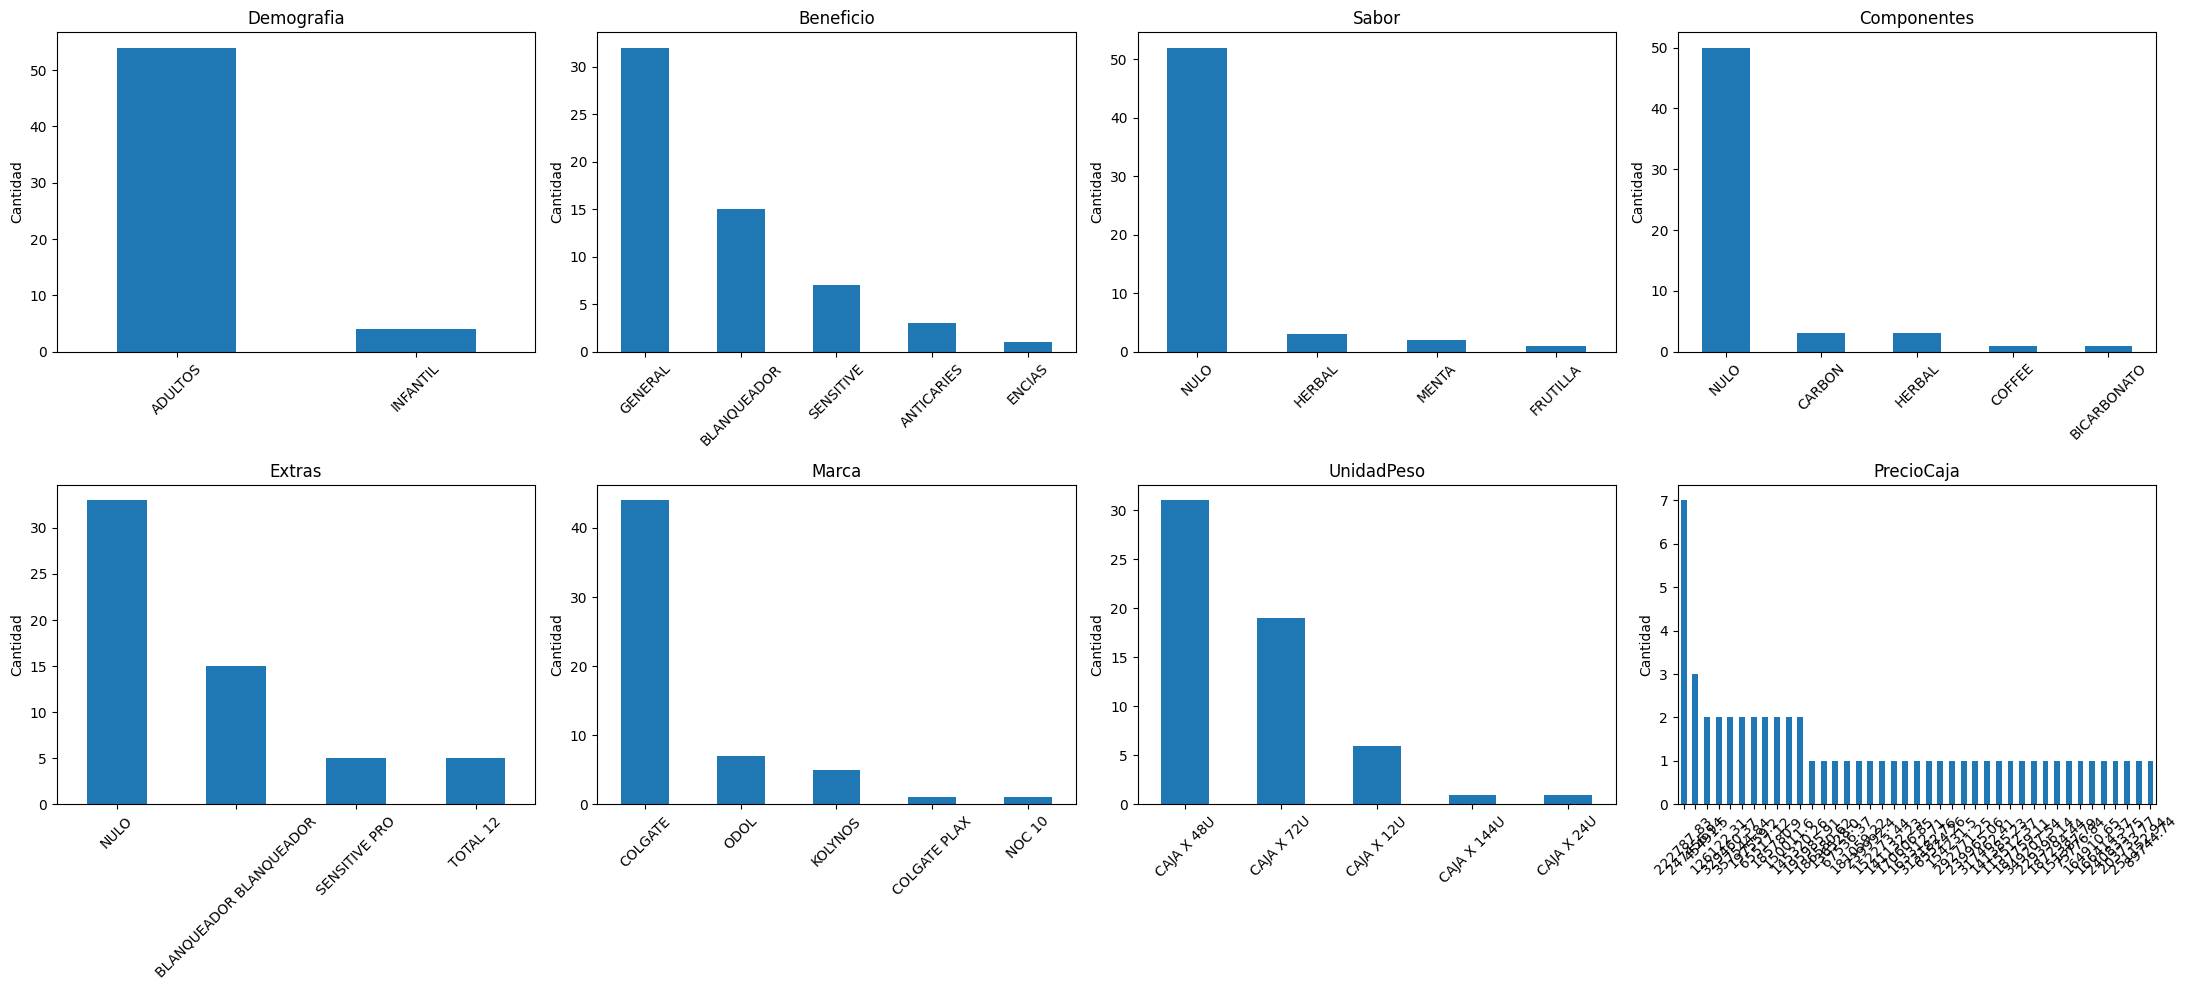

In [22]:
# @title
columnas = [
    "Demografia",
    "Beneficio",
    "Sabor",
    "Componentes",
    "Extras",
    "Marca",
    "UnidadPeso",
    "PrecioCaja"
]

fig, axes = plt.subplots(2, 4, figsize=(22, 10))

axes = axes.flatten()

for i, col in enumerate(columnas):

    conteo = productos_resultado[col].fillna("NULL").value_counts()

    conteo.plot(
        kind="bar",
        ax=axes[i]
    )

    axes[i].set_title(f"{col}")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Build a KNN model




In [24]:
# ─────────────────────────────────────────────
# 1. LOADING AND CLEANING
# ─────────────────────────────────────────────
df = productos_resultado.copy()
df_model = df.copy()

cat_cols = (
    categorias_atributo_valor["AtributoNombre"]
    .dropna()
    .astype(str)
    .str.strip()
    .drop_duplicates()
    .tolist()
)
num_cols = ["PrecioUnidad", "PrecioCaja"]

cat_cols = [
    col for col in cat_cols
    if col in df_model.columns and col not in num_cols
]

for col in cat_cols:
    df_model[col] = df_model[col].fillna("NINGUNO")

# ─────────────────────────────────────────────
# 3. CASE: consulta_query
# ─────────────────────────────────────────────
CONSULTA_VECTOR = crear_consulta_vector(
    consulta_query,
    cat_cols,
    categorias_atributo_valor,
    df_model
)
print(CONSULTA_VECTOR)

print("\n" + "="*80)
print(f"QUERY: '{consulta_query}'")
print("="*80)

escenarios = [
    ("A — Balanced          (α=0.25 β=0.50 γ=0.25)", 0.25, 0.50, 0.25),
    ("B — Strong semantic    (α=0.10 β=0.70 γ=0.20)", 0.10, 0.70, 0.20),
    ("C — Strong structural  (α=0.50 β=0.30 γ=0.20)", 0.50, 0.30, 0.20),
]

resultados_escenarios = {}

for nombre, pk, pc, pa in escenarios:
    res = recomendar_hibrido(
        consulta_texto   = consulta_query,
        consulta_vector  = CONSULTA_VECTOR,
        df_productos     = df_model,
        peso_knn         = pk,
        peso_consulta    = pc,
        peso_atributos   = pa,
        top_k            = 5
    )
    resultados_escenarios[nombre] = res

    print(f"\n{'─'*80}")
    print(f"SCENARIO {nombre}")
    print(f"{'─'*80}")

    print(res[['Rank','Denominacion','ScoreKNN_norm','ScoreConsulta_norm','ScoreAtributos_norm','ScoreHibrido']].to_string(index=False))
# ─────────────────────────────────────────────
# 4. ANALYSIS: RANKING COMPARISON
# ─────────────────────────────────────────────
print("\n" + "="*80)
print("COMPARATIVE SUMMARY — Top 5 per scenario")
print("="*80)

df_orig = df_model.sort_values('Score', ascending=False).head(5)['Denominacion'].str[:40].tolist()
esc_a = resultados_escenarios[escenarios[0][0]].head(5)['Denominacion'].str[:40].tolist()
esc_b = resultados_escenarios[escenarios[1][0]].head(5)['Denominacion'].str[:40].tolist()
esc_c = resultados_escenarios[escenarios[2][0]].head(5)['Denominacion'].str[:40].tolist()

print(f"{'Rank':<6} {'Scoring Original':<42} {'Scenario A':<42} {'Scenario B':<42} {'Scenario C'}")

n = min(5, len(df_orig), len(esc_a), len(esc_b), len(esc_c))

for i in range(n):
    print(f"#{i+1:<5} {df_orig[i]:<42} {esc_a[i]:<42} {esc_b[i]:<42} {esc_c[i]}")

{'Marca': 'NINGUNO', 'UnidadCaja': 'NINGUNO', 'UnidadMinima': 'NINGUNO', 'Gramaje': 'NINGUNO', 'Demografia': 'INFANTIL', 'Beneficio': 'NINGUNO', 'Sabor': 'NINGUNO', 'Componentes': 'NINGUNO', 'Extras': 'NINGUNO', 'PrecioUnidad': np.float64(3293.100000000001)}

CONSULTA: 'pasta dental infantil'

────────────────────────────────────────────────────────────────────────────────
ESCENARIO A — Balanceado        (α=0.25 β=0.50 γ=0.25)
────────────────────────────────────────────────────────────────────────────────
 Rank                                       Denominacion  ScoreKNN_norm  ScoreConsulta_norm  ScoreAtributos_norm  ScoreHibrido
    1   GEL  DENTAL COLGATE KIDS SMILES  BARBIE X 75 ML.       1.000000                 1.0             0.826291      0.956573
    2   CREMA DENTAL COLGATE KIDS SMILE  MINIONS X 75 ML       1.000000                 1.0             0.826291      0.956573
    3 CREMA DENTAL INFANTIL  ODOLITO  TUTTI FRUTTI X 50G       0.905465                 1.0             0.8

## KNN model evaluation





In [26]:
# ─────────────────────────────────────────────
# GROUND TRUTH
# Products considered relevant per query
# (manually defined as gold standard)
# ─────────────────────────────────────────────
ground_truth = {
    "pasta dental infantil":                                          [153,197,229,188,9053],
    "dentífrico con CHARCOAL":                                        [205,7441,8107,9052,7554],
    "baterías ENERGIZER AA":                                          [2889,2877,2878,2880,2879],
    "PILA zinc carbon":                                               [2873,2867,7497,7498,7499],
}
# ─────────────────────────────────────────────
# METRICS: Precision, Recall, Accuracy, F1
# ─────────────────────────────────────────────
def calcular_metricas(productos_resultado, consulta_query, top_n=5):
    """
    Computes Precision, Recall, Accuracy and F1-Score
    comparing the retrieved top-N against the ground truth.

    Parameters
    ----------
    productos_resultado : DataFrame with all products and their scores
    consulta_query      : query text (must exist in ground_truth)
    top_n               : evaluation cutoff (default=5)

    Returns
    -------
    dict with TP, FP, FN, TN and the 4 metrics
    """
    if consulta_query not in ground_truth:
        print(f"⚠ '{consulta_query}' is not in the ground truth")
        return None

    relevant  = set(ground_truth[consulta_query])
    retrieved = set(
        productos_resultado
        .sort_values('Score', ascending=False)
        .head(top_n)['ProductoId']
        .astype(int)
        .tolist()
    )

    N  = len(productos_resultado)
    TP = len(retrieved & relevant)
    FP = len(retrieved - relevant)
    FN = len(relevant - retrieved)
    TN = N - TP - FP - FN

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall    = TP / (TP + FN) if (TP + FN) > 0 else 0
    accuracy  = (TP + TN) / N
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) > 0 else 0)

    return {
        'Consulta':   consulta_query,
        'N':          N,
        'GT':         len(relevant),
        'TP': TP, 'FP': FP, 'FN': FN, 'TN': TN,
        'Precision':  round(precision, 2),
        'Recall':     round(recall,    2),
        'Accuracy':   round(accuracy,  2),
        'F1':         round(f1,        2),
    }


def calcular_metricas_hibrido(resultados_escenarios, consulta_query,
                               productos_resultado, top_n=5):
    """
    Computes metrics for each hybrid scenario + original scoring.

    Parameters
    ----------
    resultados_escenarios : dict of scenario_name → DataFrame (output of recomendar_hibrido)
    consulta_query        : query text
    productos_resultado   : original DataFrame with Score column
    top_n                 : evaluation cutoff

    Returns
    -------
    DataFrame with one row per model and metric columns
    """
    if consulta_query not in ground_truth:
        print(f"⚠ '{consulta_query}' is not in the ground truth")
        return None

    relevant = set(ground_truth[consulta_query])
    N        = len(productos_resultado)
    filas    = []

    # Original scoring
    ids_orig = (productos_resultado
                .sort_values('Score', ascending=False)
                .head(top_n)['ProductoId']
                .astype(int).tolist())
    retrieved = set(ids_orig)
    TP = len(retrieved & relevant); FP = len(retrieved - relevant)
    FN = len(relevant - retrieved); TN = N - TP - FP - FN
    prec = TP/(TP+FP) if TP+FP>0 else 0
    rec  = TP/(TP+FN) if TP+FN>0 else 0
    acc  = (TP+TN)/N
    f1   = 2*prec*rec/(prec+rec) if prec+rec>0 else 0
    filas.append({'Modelo':'Scoring Original',
                  'TP':TP,'FP':FP,'FN':FN,'TN':TN,
                  'Precision':round(prec,2),'Recall':round(rec,2),
                  'Accuracy':round(acc,2),'F1':round(f1,2)})

    # Hybrid scenarios
    for nombre_esc, df_res in resultados_escenarios.items():
        ids = df_res['ProductoId'].astype(int).tolist()
        retrieved = set(ids[:top_n])
        TP = len(retrieved & relevant); FP = len(retrieved - relevant)
        FN = len(relevant - retrieved); TN = N - TP - FP - FN
        prec = TP/(TP+FP) if TP+FP>0 else 0
        rec  = TP/(TP+FN) if TP+FN>0 else 0
        acc  = (TP+TN)/N
        f1   = 2*prec*rec/(prec+rec) if prec+rec>0 else 0

        # Extract only the scenario letter for the name
        #label = nombre_esc.split('—')[0].strip() if '—' in nombre_esc else nombre_esc
        filas.append({'Modelo': 'Scenario ' + nombre_esc,
                      'TP':TP,'FP':FP,'FN':FN,'TN':TN,
                      'Precision':round(prec,2),'Recall':round(rec,2),
                      'Accuracy':round(acc,2),'F1':round(f1,2)})

    return pd.DataFrame(filas)

In [27]:
# ─────────────────────────────────────────────
# USAGE — for the different scenarios
# ─────────────────────────────────────────────
metricas = calcular_metricas_hibrido(
    resultados_escenarios,
    consulta_query,
    productos_resultado,
    top_n=5
)

print(f"\n{'='*70}")
print(f"EVALUATION METRICS — Query: '{consulta_query}'")
print(f"{'='*70}")
display(metricas.style.hide(axis='index'))


MÉTRICAS DE EVALUACIÓN — Consulta: 'pasta dental infantil'


Modelo,TP,FP,FN,TN,Precision,Recall,Accuracy,F1
Scoring Original,4,1,1,52,0.800000,0.800000,0.970000,0.800000
Escenario A — Balanceado (α=0.25 β=0.50 γ=0.25),4,1,1,52,0.800000,0.800000,0.970000,0.800000
Escenario B — Semántico fuerte (α=0.10 β=0.70 γ=0.20),4,1,1,52,0.800000,0.800000,0.970000,0.800000
Escenario C — Estructural fuerte(α=0.50 β=0.30 γ=0.20),4,1,1,52,0.800000,0.800000,0.970000,0.800000


## Metrics charts


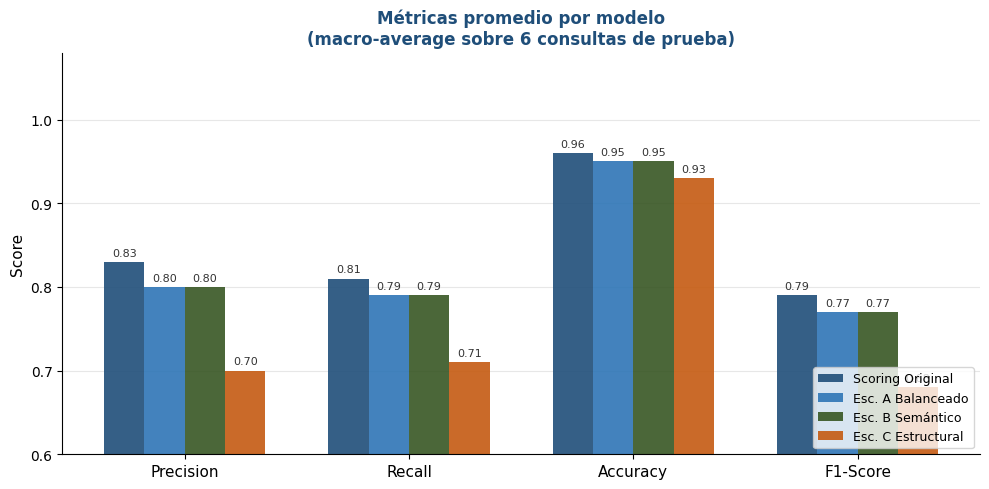

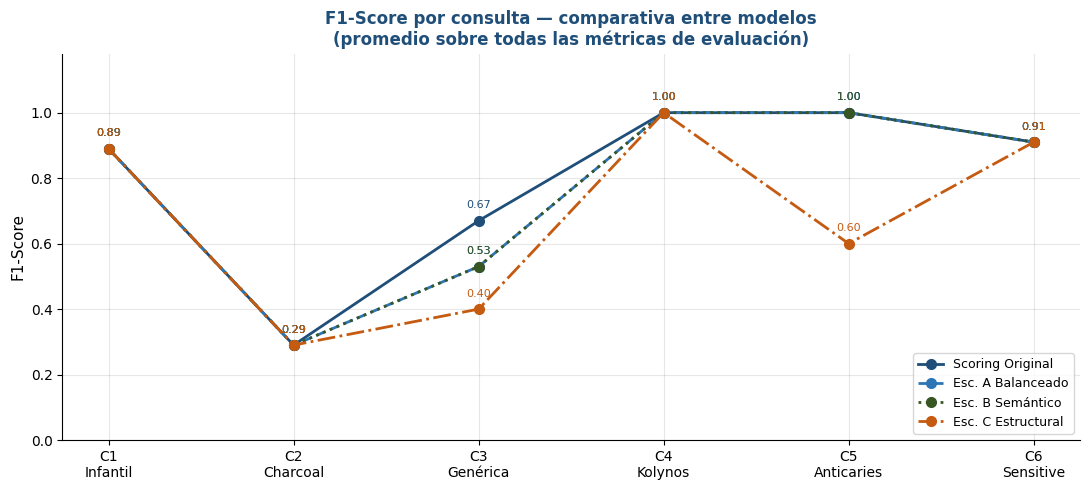

In [28]:
# @title
# ── Data ─────────────────────────────────────────────────────────────────────
ORIG  = '#1F4E79'
ESC_A = '#2E75B6'
ESC_B = '#375623'
ESC_C = '#C55A11'

colores = [ORIG, ESC_A, ESC_B, ESC_C]
modelos = ['Scoring Original', 'Sc. A Balanced', 'Sc. B Semantic', 'Sc. C Structural']
metricas = ['Precision', 'Recall', 'Accuracy', 'F1-Score']

valores = [
    [0.83, 0.81, 0.96, 0.79],   # Scoring Original
    [0.80, 0.79, 0.95, 0.77],   # Scenario A
    [0.80, 0.79, 0.95, 0.77],   # Scenario B
    [0.70, 0.71, 0.93, 0.68],   # Scenario C
]

consultas   = ['C1\nKids', 'C2\nCharcoal', 'C3\nGeneric', 'C4\nKolynos', 'C5\nAnticavity', 'C6\nSensitive']
lstyles     = ['-', '--', ':', '-.']

f1s = [
    [0.89, 0.29, 0.67, 1.00, 1.00, 0.91],   # Scoring Original
    [0.89, 0.29, 0.53, 1.00, 1.00, 0.91],   # Scenario A
    [0.89, 0.29, 0.53, 1.00, 1.00, 0.91],   # Scenario B
    [0.89, 0.29, 0.40, 1.00, 0.60, 0.91],   # Scenario C
]

# ── Chart 1: Grouped bars ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(metricas))
w = 0.18

for j, (modelo, vals, c) in enumerate(zip(modelos, valores, colores)):
    bars = ax.bar(x + j * w, vals, w, label=modelo, color=c, alpha=0.9)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{v:.2f}', ha='center', va='bottom', fontsize=8, color='#333')

ax.set_xticks(x + w * 1.5)
ax.set_xticklabels(metricas, fontsize=11)
ax.set_ylim(0.60, 1.08)
ax.set_ylabel('Score', fontsize=11)
ax.set_title(
    'Average metrics per model\n(macro-average over 6 test queries)',
    fontsize=12, fontweight='bold', color='#1F4E79'
)
ax.legend(fontsize=9, loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
plt.close()

# ── Chart 2: F1-Score per query ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))

for vals, c, ls, modelo in zip(f1s, colores, lstyles, modelos):
    ax.plot(consultas, vals, 'o' + ls, color=c, linewidth=2,
            markersize=7, label=modelo)
    for j, v in enumerate(vals):
        ax.annotate(f'{v:.2f}', (consultas[j], v),
                    textcoords='offset points', xytext=(0, 9),
                    ha='center', fontsize=8, color=c)

ax.set_ylim(0, 1.18)
ax.set_ylabel('F1-Score', fontsize=11)
ax.set_title(
    'F1-Score per query — model comparison\n(average over all evaluation metrics)',
    fontsize=12, fontweight='bold', color='#1F4E79'
)
ax.legend(fontsize=9, loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(os.path.join(base_path, 'chart_bars.png'), dpi=150, bbox_inches='tight', facecolor='white')
plt.savefig(os.path.join(base_path, 'chart_f1.png'), dpi=150, bbox_inches='tight', facecolor='white')

plt.show()
plt.close()

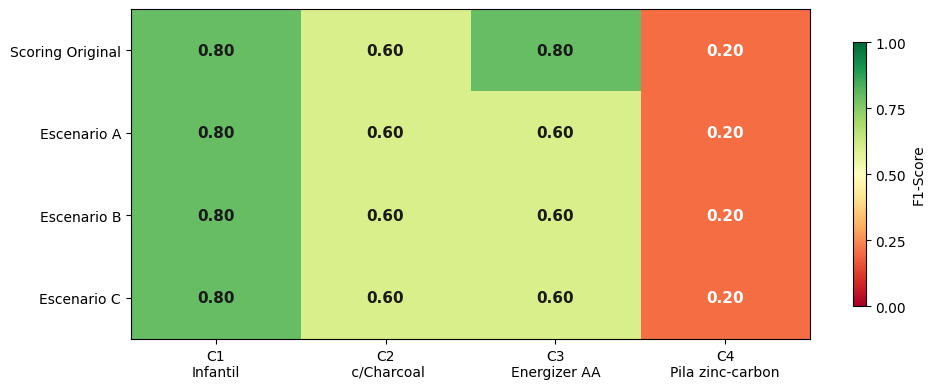

In [29]:
# ── Data ─────────────────────────────────────────────────────────────────────
modelos   = ['Original Scoring', 'Scenario A', 'Scenario B', 'Scenario C']
consultas = ['C1\nKids', 'C2\n w/ Charcoal', 'C3\nEnergizer AA', 'C4\nZinc-carbon battery']

f1data = np.array([
    [0.80, 0.60, 0.80, 0.20],   # Scoring Original
    [0.80, 0.60, 0.60, 0.20],   # Scenario A
    [0.80, 0.60, 0.60, 0.20],   # Scenario B
    [0.80, 0.60, 0.60, 0.20],   # Scenario C
])

# ── Chart ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))

im = ax.imshow(f1data, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')

# Labels in each cell
for i in range(len(modelos)):
    for j in range(len(consultas)):
        color = 'white' if f1data[i, j] < 0.45 else '#1a1a1a'
        ax.text(j, i, f'{f1data[i, j]:.2f}',
                ha='center', va='center',
                fontsize=11, fontweight='bold', color=color)

ax.set_xticks(range(len(consultas)))
ax.set_xticklabels(consultas, fontsize=10)
ax.set_yticks(range(len(modelos)))
ax.set_yticklabels(modelos, fontsize=10)

# Colorbar
cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('F1-Score', fontsize=10)
cbar.set_ticks([0, 0.25, 0.50, 0.75, 1.0])
"""
ax.set_title(
    'Heatmap — F1-Score per query/model',
    fontsize=12, fontweight='bold', color='#1F4E79'
)
"""
plt.tight_layout()
plt.savefig(os.path.join(base_path, 'chart_heatmap.png'),
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
plt.close()

## Generate Categorias_Atributos_Valor from categoria_resultados


In [30]:
def build_categorias_atributo_valor(
    categorias_resultado: pd.DataFrame,
    cat_atributos: pd.DataFrame,
    atributos: pd.DataFrame,
    cat_atr_valor: pd.DataFrame,
) -> pd.DataFrame:

    # ── Step 1: categorias_resultado → Categorias_Atributos ──────────────────
    merged = categorias_resultado.merge(
        cat_atributos,
        left_on  = 'iddbprca',
        right_on = 'Subcategoria',
        how      = 'inner'
    )

    # ── Step 2: → Atributos ──────────────────────────────────────────────────
    merged = merged.merge(
        atributos,
        on  = 'AtributoId',
        how = 'left'
    )

    # ── Step 3: → Categorias_Atributos_Valor ─────────────────────────────────
    merged = merged.merge(
        cat_atr_valor,
        on  = 'CatAtrId',
        how = 'left'
    )

    return merged.reset_index(drop=True)


# ── Call ───────────────────────────────────────────────────────────────────
categorias_atributo_valor = build_categorias_atributo_valor(
    categorias_resultado,
    cat_atributos,
    atributos,
    cat_atr_valor
)

categorias_atributo_valor = categorias_atributo_valor[[
    'Categoria', 'Subcategoria', 'AtributoId', 'PesoAtributo',
    'AtributoNombre', 'Valor', 'ValorDefault', 'PesoValor'
]]

display(categorias_atributo_valor.head(5).style.hide(axis='index'))

Categoria,Subcategoria,AtributoId,PesoAtributo,AtributoNombre,Valor,ValorDefault,PesoValor
262,241,1,1.000000,Marca,ODOL,nan,1.000000
262,241,2,0.100000,UnidadCaja,CAJA X 12U,nan,0.250000
262,241,2,0.100000,UnidadCaja,CAJA X 48U,nan,0.250000
262,241,2,0.100000,UnidadCaja,CAJA X 72U,nan,0.250000
262,241,3,0.050000,UnidadMinima,UNIDADES,UNIDADES,0.000000
